# Tutorial: Source extraction with the SEP package

<br>
<br>
<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) European Space Agency, 2026.

This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.

</div>

**Last modified:** 2026-11-11

**Last update:** DR1-Foundation major update.

**Notebook summary**

This example notebook presents a simple example use case for extracting sources from a Euclid image with the Python [SEP package](https://sep.readthedocs.io/en/stable/) (Python library for Source Extraction and Photometry) and making cutouts for those sources. **The notebook can currently be used in the PDR archive environments**. In this case the sources we want to make cutouts from are all on the same image and we have the image available in ESA Datalabs in a data volume. The sources are extracted with SEP and cutouts are made with the [Astropy](https://docs.astropy.org/en/stable/index.html) function Cutout2D. We also provide an example how to overlay sources from the MER catalogue on the same image area as a comparison. The steps are:

* Step 1 Taking a look at the example image
* Step 2 Extracting sources from a part of the image with the SEP package that is based on Source Extractor
* Step 3 Overlaying MER catalogue sources on the image as comparison
* Step 4 Making a cutout of one source
* Step 5 Making a cutout of the full list of sources automatically
* Extra: Converting FITS file cutouts to jpgs

**Useful links:**

* [Euclid DR1 data product description](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [DR1 data release homepage](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)
* [SEP package documentation](https://sep.readthedocs.io/en/stable/)


**Running the notebook:** This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included.

***

**Importing necessary packages**

In [1]:
from astroquery.esa.euclid import Euclid

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.nddata.utils import Cutout2D
from astropy import wcs
from astropy.io import fits
from PIL import Image
import pandas as pd
import numpy as np
import sep, glob, os, sys, copy

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.text import Text
from astropy.visualization import astropy_mpl_style, ImageNormalize, ZScaleInterval, PercentileInterval, AsinhStretch, SqrtStretch, SquaredStretch

import n_utils as utils
plt.style.use(astropy_mpl_style)

First let's make a folder (if not already created) to save the output files from this notebook. All the example notebooks save their outputs to this same folder in your user workspace called: `'example_notebook_outputs/'`

In [2]:
#make a folder in your workspace for the output files
output_folder = '/media/user/example_notebook_outputs/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

**Please note:** When comparing the Q1 and DR1-foundation data releases:
* some table and column names will be different
* specific example source coordinates

It is possible to login using many different options - see the # [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) method for details. Similarly to the archive website for safety reasons this login expires after a period of time. Once this happens the queries to the archive will fail (seemingly without reason). If you are running a personal notebook that requires you to stay logged in for longer - make sure to execute this code line again every once in a while. 

In [3]:
# Alternative ways to login; uncomment your preferred one: ===========
Euclid.login()
# Euclid.login_gui()                                          # Login via graphic interface (pop-up window)
# Euclid.login(user='<user name>', password='<password>')     # 
# Euclid.logout()

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  hcanovas
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid sia service: eas.esac.esa.int:443/sas-sia/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


In [4]:
schema = 'dr1'   # DR1 schema. Change to "q1" to retrieve Q1 data, but please note that the target table names should be adapted accordingly. 

## Step 0. Getting an image to work with

In [5]:
# depending on the archive release, use different part of the sky in example
coords = SkyCoord("17h48m18.89s +65d35m57.26s", frame='icrs')
print("Coordinates of the source are:", coords.ra.deg, coords.dec.deg)

Coordinates of the source are: 267.07870833333334 65.59923888888889


In [6]:
# getting the mosaic file covering the defined coordinates

query= f"""SELECT TOP 1 file_name, file_path, datalabs_path, mosaic_product_oid, tile_index, instrument_name, filter_name, ra AS image_ra, dec AS image_dec, processing_mode, DISTANCE(ra, dec, {coords.ra.deg}, {coords.dec.deg}) AS dist
FROM {schema}.mosaic_product AS mosaics
WHERE INTERSECTS(CIRCLE({coords.ra.deg}, {coords.dec.deg}, 0.008333333333333333), fov)=1
AND instrument_name = 'VIS'
ORDER BY tile_index"""

job = Euclid.launch_job_async(query, verbose=False)
job_table = job.get_results()
job_table

INFO: Query finished. [astroquery.utils.tap.core]


file_name,file_path,datalabs_path,mosaic_product_oid,tile_index,instrument_name,filter_name,image_ra,image_dec,processing_mode,dist
object,object,object,int64,int64,object,object,float64,float64,object,float64
EUC_MER_BGSUB-MOSAIC-VIS_TILE101832847-B9A49D_20250828T183824.671571Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101832847/VIS,/data/euclid_idr1/DR1/R1/MER/101832847/VIS,128826,101832847,VIS,VIS,266.9232075129,65.5,DEEP,0.11828304925778715


In [7]:
# constructing file path from the table info
file_path = job_table['datalabs_path'][0] + '/' + job_table['file_name'][0]
print('Using file:', file_path)

Using file: /data/euclid_idr1/DR1/R1/MER/101832847/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101832847-B9A49D_20250828T183824.671571Z_00.00.fits


## Step 1. Taking a look at the example image

When displaying the image we can combine Matplotlib imshow with astropy.visualization functions for image stretching and normalization. In the cell below we are using ZScaleInterval() and SquaredStretch(). ZScaleInterval() is an implementation of IRAF's ZScale Algorithm. According to the IRAF's documentation, the algorithm was designed to display the image values near the median image value without the time-consuming process of computing a full image histogram. Astropy.visualization also provides a list of other options for normalization and stretching functions. If you are interested in more examples, then here is some great [Astropy documentation](https://docs.astropy.org/en/stable/visualization/normalization.html#intervals-and-normalization) on the topic.

**Notes:** Plotting large images is time consuming in Python. To speed up this process, the original Euclid image displayed below has been sampled by a factor of x10.

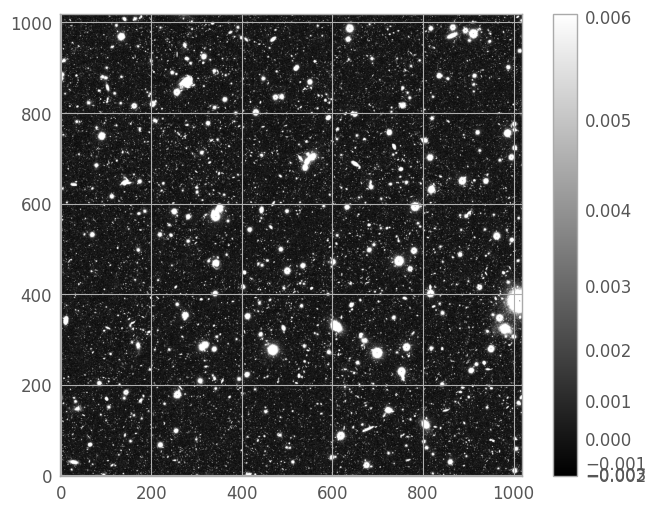

In [8]:
#plotting the full downloaded file
hdul           = fits.open(file_path)
image_data_big = hdul[0].data
header         = hdul[0].header

image_data_undersamp = image_data_big[::10, ::10]

plt.figure()
plt.imshow(image_data_undersamp, cmap='gray', origin='lower', norm=ImageNormalize(image_data_undersamp, interval=ZScaleInterval(), stretch=SquaredStretch()))
plt.colorbar();

## Step 2. Extracting sources from a part of the image with the SEP python package

Since extracting the sources from the full image is computationally very heavy then from now on we will be working with a representative smaller part of the image (that has been selected to have a variety of different sources). For performing source extraction on the image we use a Python library for Source Extraction and Photometry - SEP. SEP makes the core algorithms of Source Extractor (Bertin & Arnouts 1996) available as a library of stand-alone functions and classes. A tutorial for using sep for source extraction can be found here: https://sep.readthedocs.io/en/v1.0.x/tutorial.html.

The code below makes use of the [Astropy.Cutout2D](https://docs.astropy.org/en/stable/api/astropy.nddata.Cutout2D.html) method.

In [9]:
# extracting smaller area
cutout     = Cutout2D(data=image_data_big, position = coords, size=(1500,1500), wcs=wcs.WCS(header))
data       = cutout.data
small_data = data.byteswap().view(data.dtype.newbyteorder())

For the interested reader: as mentioned [here in the SEP documentation](https://sep.readthedocs.io/en/stable/tutorial.html#Finally-a-brief-word-on-byte-order) the byteswap operation above is necessary because we are using astropy.io.fits to read the image. The package always returns big-endian byte order arrays, even on little-endian machines. This is due to the FITS standard requiring big-endian array.

Noticea also how we overwrite the data_sub variable by doing `data_sub = data_sub - bkg` - this coding practice is mainly used for memory efficiency. If we were to create a new varible instead (and never use the intermediate one again) then we would use double the memory. This is not critical in this specific notebook but when working with large images it is a good thing to keep in mind. See also this [FAQ page about memory](https://s2e2.cosmos.esa.int/confluence/spaces/EK/pages/1424361534/Why+do+I+get+a+Kernel+Restarting+error+when+analysing+Euclid+images+in+ESA+Datalabs).

In [10]:
#background subtraction
data_sub = np.ascontiguousarray(small_data)
bkg      = sep.Background(data_sub)
data_sub = data_sub - bkg

#source extraction
sources     = sep.extract(data_sub, 1.5, err=bkg.globalrms, minarea=200, deblend_cont=1.0)
sources_thr = sources[sources['flux'] > 50]
print("Found", len(sources_thr), "objects above flux threshold")

Found 15 objects above flux threshold


The result of the source extraction is a number of sources that correspond to the criteria that were set. The information about these sources is in `sources_thr` which is a NumPy array containing 30 information fields for each source. One of these fields contains information about the centre coordinates of each source which we will use to make cutouts in the next step.

We can convert the `sources_thr` to a pandas dataframe for better access and visualization.

In [11]:
sep_sources_df = pd.DataFrame(data=sources_thr, columns=sources_thr.dtype.names)
sep_sources_df

,thresh,npix,tnpix,xmin,xmax,ymin,ymax,x,y,x2,...,cxy,cflux,flux,cpeak,peak,xcpeak,ycpeak,xpeak,ypeak,flag
0,0.001165,13785,12871,1295,1485,116,260,1364.970341,191.287772,68.581867,...,-0.010046,2047.243042,2047.668945,169.515320,287.103638,1365,191,1365,191,0
1,0.001165,11450,10973,0,104,196,366,13.299672,272.121075,372.727451,...,-0.006061,522.211426,531.472900,5.308371,10.513825,5,266,4,269,2
2,0.001165,24373,23397,442,661,418,612,535.732511,527.293370,443.708800,...,-0.001497,1552.069092,1552.481079,7.710843,14.672652,539,525,538,525,0
3,0.001165,3303,2998,1089,1160,622,700,1128.962838,659.046561,11.005129,...,0.022701,325.333099,325.466675,28.874203,53.015099,1129,659,1129,659,0
4,0.001165,55468,53580,571,883,601,917,745.199385,749.468200,2707.803864,...,-0.000358,1001.778809,1002.717651,1.081415,1.328901,748,754,748,754,0
5,0.001165,15571,14592,365,559,891,1051,434.448957,958.398897,319.789939,...,0.022075,2124.888672,2125.283936,175.053192,310.136658,431,959,431,959,0
6,0.001165,15721,14864,1295,1467,909,1061,1360.851523,992.934231,149.917622,...,0.001140,2126.988281,2127.336426,177.918686,340.380310,1360,997,1360,997,0
7,0.001165,3863,3674,1078,1152,1135,1208,1114.097053,1173.383503,75.410071,...,-0.004443,80.179062,80.286774,1.348452,1.771088,1115,1174,1115,1174,0
8,0.001165,5811,5466,795,881,1113,1213,839.490826,1166.106412,210.634742,...,-0.004684,132.324203,132.481979,1.570853,2.532716,866,1185,866,1185,0
9,0.001165,2493,2262,1237,1298,1196,1270,1268.057468,1239.767152,7.945624,...,0.007462,255.452484,255.591797,23.450127,43.279926,1268,1240,1268,1240,0


In [12]:
print("The pixel coordinates for the first source are:", sep_sources_df.loc[0, 'x'], sep_sources_df.loc[0, 'y'])

The pixel coordinates for the first source are: 1364.970340657555 191.28777171812894


### Plotting the extracted sources on the image

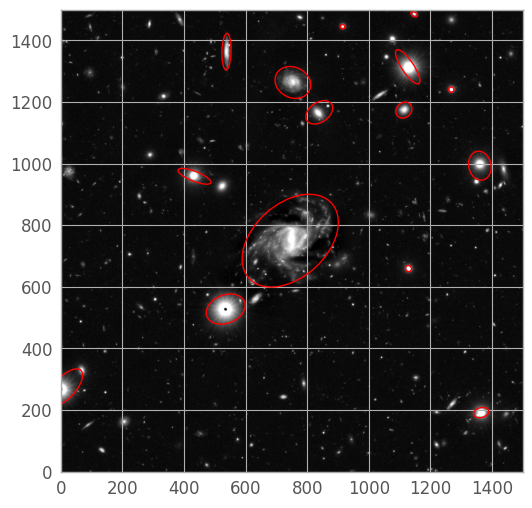

In [13]:
#plotting found sources

# plot background-subtracted image
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, cmap='gray', origin='lower', norm=ImageNormalize(small_data, interval=PercentileInterval(99.5), stretch=AsinhStretch()))

# plot an ellipse for each object
for i in range(len(sep_sources_df)):
    e = Ellipse(xy=(sep_sources_df.loc[i, 'x'], sep_sources_df.loc[i, 'y']),
                width=6*sep_sources_df.loc[i, 'a'],
                height=6*sep_sources_df.loc[i, 'b'],
                angle=sep_sources_df.loc[i, 'theta'] * 180. / np.pi)
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)

## Step 3. Overlaying MER catalogue sources on the image as comparison

As a comparison to our source extraction we can create an overlay of the sources in the same area from the MER catalogue. First we make a query for the sources taking the large galaxy as a central point and then we can plot the sources on the image. As an added exercise we can plot all the sources that have spectra data with a yellow line and also write their photometric redshift on the image. 

The catalogue query we are making below combines the main information about the source from the MER catalogue to the phz_photo_z catalogue to get the photometric redshift and the spectra_source catalogue to get information about the spectra file of the source. Note that we are using a flux treshold in the query to get a similar result to the sources we extracted ourselves previously. If you are interested in looking at all sources for this area in the MER catalogue you can remove the flux requirement part.

Also note that the query involves a box-like search on the sky that takes into account projection effects.

In [14]:
flux_col_name = 'flux_vis_sersic'
flux_lim      = 5
box_hs        = (1.5/60)/2. # Box half-size (degrees)

query = f"""SELECT mer.right_ascension, mer.declination, mer.segmentation_area, {flux_col_name}, mer.kron_radius, mer.segmentation_map_id, mer.ellipticity, mer.semimajor_axis, mer.semimajor_axis * (1-mer.ellipticity) AS semiminor_axis,
            mer.position_angle, photoz.phz_median, spec.file_name AS spec_filename, spec.datalabs_path AS spec_datalabs_path, spec.hdu_index AS spec_hdu_id
            FROM {schema}.mer_catalogue_deep_survey AS mer
            JOIN {schema}.phz_photo_z_deep_survey AS photoz ON mer.object_id=photoz.object_id
            JOIN {schema}.spectra_source AS spec ON mer.object_id = spec.source_id
            WHERE
            mer.right_ascension BETWEEN ({coords.ra.deg} - {box_hs}/COS(RADIANS({coords.dec.deg}))) AND ({coords.ra.deg} + {box_hs}/COS(RADIANS({coords.dec.deg})))  AND 
            mer.declination BETWEEN ({coords.dec.deg} - {box_hs}) AND ({coords.dec.deg} + {box_hs})
            AND NULLIF({flux_col_name}, 'NaN') > {flux_lim}"""

source_results_spec = utils.get_query_results(Euclid, query, display_table=False)

# keeping only sources within footprint of the image
mask = SkyCoord(source_results_spec['right_ascension'], source_results_spec['declination'], frame='icrs', unit="deg").contained_by(cutout.wcs)
source_results_spec = source_results_spec[mask]

print("Found " + str(len(source_results_spec)) + " sources from catalogue")
source_results_spec 

ADQL query: 
SELECT mer.right_ascension, mer.declination, mer.segmentation_area, flux_vis_sersic, mer.kron_radius, mer.segmentation_map_id, mer.ellipticity, mer.semimajor_axis, mer.semimajor_axis * (1-mer.ellipticity) AS semiminor_axis,
            mer.position_angle, photoz.phz_median, spec.file_name AS spec_filename, spec.datalabs_path AS spec_datalabs_path, spec.hdu_index AS spec_hdu_id
            FROM dr1.mer_catalogue_deep_survey AS mer
            JOIN dr1.phz_photo_z_deep_survey AS photoz ON mer.object_id=photoz.object_id
            JOIN dr1.spectra_source AS spec ON mer.object_id = spec.source_id
            WHERE
            mer.right_ascension BETWEEN (267.07870833333334 - 0.0125/COS(RADIANS(65.59923888888889))) AND (267.07870833333334 + 0.0125/COS(RADIANS(65.59923888888889)))  AND 
            mer.declination BETWEEN (65.59923888888889 - 0.0125) AND (65.59923888888889 + 0.0125)
            AND NULLIF(flux_vis_sersic, 'NaN') > 5

INFO: Query finished. [astroquery.utils.tap.

right_ascension,declination,segmentation_area,flux_vis_sersic,kron_radius,segmentation_map_id,ellipticity,semimajor_axis,semiminor_axis,position_angle,phz_median,spec_filename,spec_datalabs_path,spec_hdu_id
deg,deg,pix,uJy,pix,NA,NA,pix,,deg,NA,,,
float64,float64,int32,float64,float64,int64,float64,float64,float64,float64,float64,object,object,int64
267.0787291453002,65.59918973573954,100004,900.201171875,470.22784423828125,101832847049845,0.2116689383983612,67.17540740966797,52.95646023678614,-59.78666305541992,0.019999999552965164,EUC_SIR_W-COMBSPEC_101832847_20250908T222834.286792Z.fits,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832847,8052
267.072931829222,65.6107664169617,8535,58.57514953613281,142.8069610595703,101832847053358,0.39702367782592773,20.4009952545166,12.301317087259122,-54.46342086791992,0.2199999988079071,EUC_SIR_W-COMBSPEC_101832847_20250908T223647.170579Z.fits,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832847,7915
267.05158102330364,65.58692077501581,746,5.094183921813965,34.855735778808594,101832847047876,0.11123009771108627,4.979390621185303,4.425532515849195,84.01608276367188,0.800000011920929,EUC_SIR_W-COMBSPEC_101832847_20250908T222556.394641Z.fits,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832847,7863
267.108532617821,65.5939157000915,502,12.104401588439941,14.749870300292969,101832847049373,0.05241362005472183,2.1071243286132812,1.996682314645284,-9.691682815551758,0.8100000023841858,EUC_SIR_W-COMBSPEC_101832847_20250908T222834.286792Z.fits,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832847,8418
267.05421658512466,65.6110477174421,4714,50.77596664428711,71.7208251953125,101832847053931,0.16936975717544556,10.245832443237305,8.5104982902659,-38.68476104736328,0.3199999928474426,EUC_SIR_W-COMBSPEC_101832847_20250908T223825.007224Z.fits,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832847,8519
267.05316762851356,65.59674947985783,3248,155.4847412109375,23.529390335083008,101832847049976,0.06463504582643509,3.361341714859009,3.144081239080789,-56.4505729675293,0.5400000214576721,EUC_SIR_W-COMBSPEC_101832847_20250908T222834.286792Z.fits,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832847,7822
267.09399621151164,65.60412551011973,4962,52.147796630859375,70.89472198486328,101832847051766,0.11161421239376068,10.127817153930664,8.997408819026674,-45.51576614379883,0.30000001192092896,EUC_SIR_W-COMBSPEC_101832847_20250908T223446.760318Z.fits,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832847,10101
267.0931885148776,65.59303685035452,37967,1918.4876708984375,149.36880493164062,101832847049843,0.109098419547081,21.338401794433594,19.01041588300029,-13.332571983337402,0.07999999821186066,EUC_SIR_W-COMBSPEC_101832847_20250908T222834.286792Z.fits,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832847,8174


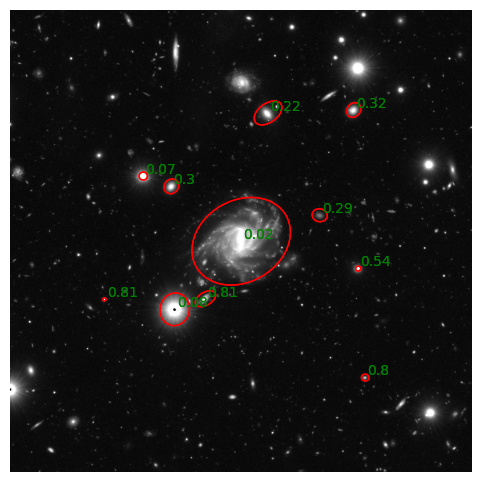

In [15]:
# plot the image with catalogue sources
fig, ax = plt.subplots()
im = ax.imshow(cutout.data, cmap='gray', origin='lower', norm=ImageNormalize(cutout.data, interval=PercentileInterval(99.5), stretch=AsinhStretch()))

# plot an ellipse for each object
for source in source_results_spec:
    px, py = cutout.wcs.wcs_world2pix(source['right_ascension'], source['declination'], 1) 

    add = 90
    e = Ellipse(xy=(px, py),
                width=5*source['semimajor_axis'],
                height=5*source['semiminor_axis'],
                angle=source['position_angle']+add,
                facecolor = 'none')
    
    # yellow if source has spectrum file otherwise red
    if type(source['spec_filename']) is np.str_:
        e.set_edgecolor('yellow')
    else:
        e.set_edgecolor('red')
    
    #if source has photometric redshift value - write it as text
    if type(source['phz_median']) == np.float64:
        text = Text(x=px+7, y=py+7, text=str(round(source['phz_median'], 2)), color="Green", fontsize=10)
        ax.add_artist(text)
        
    ax.add_artist(e)
    
_ = plt.axis('off')

## Step 4. Making a cutout of largest source we extracted

As the next step we can make the cutouts simply with Astropy. Something to remember is that the source coordinates SEP returned are with respect to to the smaller area of the image (`small_data`). So we are going to use `small_data` to make the cutout. To make the cutout from the full original image `image_data` the coordinates have to be recalculated.

In [16]:
#making and saving the cutout
largest_source_idx = np.argmax(sources_thr['npix'])
cutout_single      = Cutout2D(data=small_data, position = (sources_thr[largest_source_idx]['x'], sources_thr[largest_source_idx]['y']), size= 0.7 * u.arcmin, wcs=wcs.WCS(header))
hdu = fits.PrimaryHDU(cutout_single.data)
hdu.writeto(output_folder + "test_cutout_example2.fits", overwrite=True)

Image size: (420, 420)


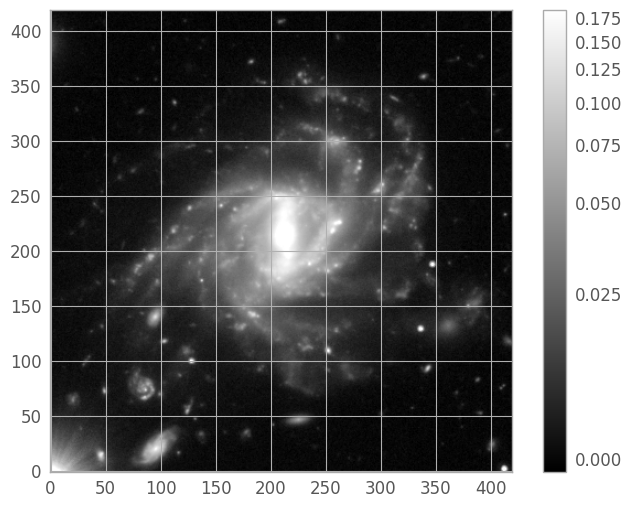

In [17]:
#taking a look at what we made
hdul = fits.open(output_folder + 'test_cutout_example2.fits')
image_data = hdul[0].data
print("Image size:", image_data.shape)

plt.figure()
plt.imshow(image_data, cmap='gray', origin='lower', norm=ImageNormalize(image_data, interval=PercentileInterval(99.5), stretch=AsinhStretch()))
plt.colorbar();

### Step 5. Making a cutout of the full list of sources automatically

Next we perform the same cutout process iterating over all of the extracted sources.

In [18]:
for i, source in enumerate(sources_thr):
    print('Making cutout number:', str(i) + '/' + str(len(sources_thr)))
    cut = Cutout2D(data=small_data, position = (source['x'], source['y']), size= 0.3 * u.arcmin, wcs=wcs.WCS(header))
        
    hdu = fits.PrimaryHDU(cut.data)
    hdu.writeto(output_folder + 'extract_cut{0}.fits'.format(str(i).zfill(2)), overwrite=True)

Making cutout number: 0/15
Making cutout number: 1/15
Making cutout number: 2/15
Making cutout number: 3/15
Making cutout number: 4/15
Making cutout number: 5/15
Making cutout number: 6/15
Making cutout number: 7/15
Making cutout number: 8/15
Making cutout number: 9/15
Making cutout number: 10/15
Making cutout number: 11/15
Making cutout number: 12/15
Making cutout number: 13/15
Making cutout number: 14/15


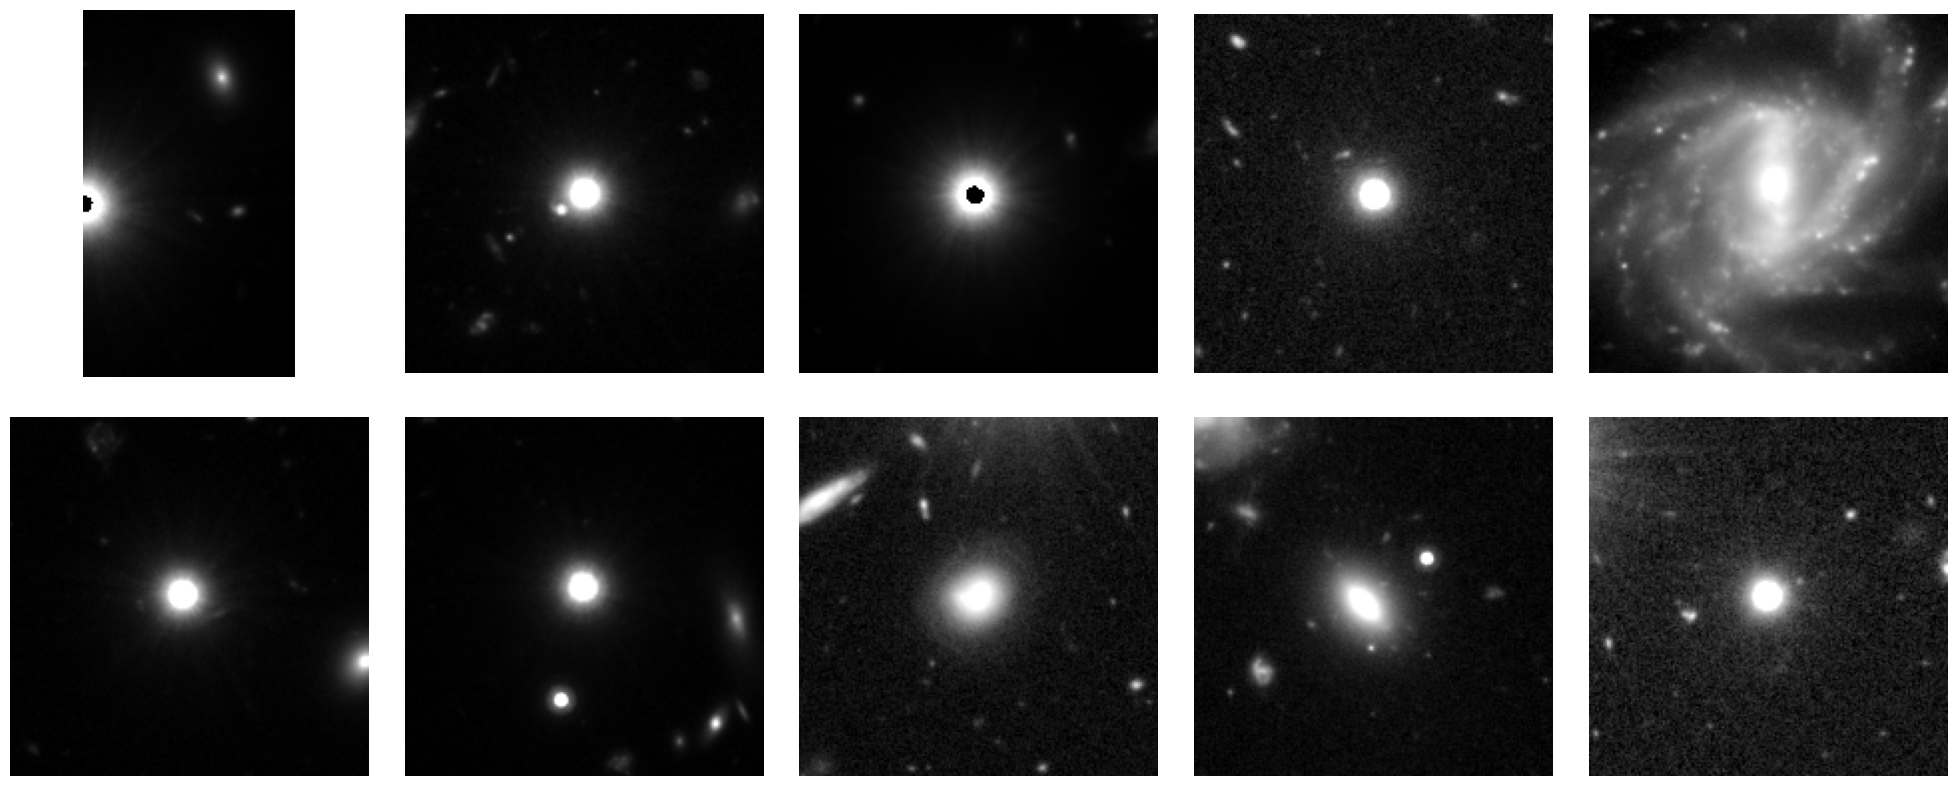

In [19]:
#showing 10 of the cutouts
files = glob.glob(output_folder + 'extract_cut*.fits')

_, axes = plt.subplots(2, 5, figsize=(25, 10))
plt.subplots_adjust(wspace=0.1, hspace=0.1)
for ax, img_path in zip(axes.flatten(), files):
    image_data = fits.getdata(img_path, ext=0)
    ax.imshow(image_data, cmap='gray', origin='lower', norm=ImageNormalize(image_data, interval=PercentileInterval(99.), stretch=AsinhStretch()))
    ax.axis("off")

## (Extra) Converting FITS file cutouts to jpgs

Below is one example of how to convert FITS files to jpgs and if necessary downsize them to create thumbnails.

**Creating another cutout to use**

First we make another larger cutout `convert_cutout.fits` for one of the sources we extracted before. This is the file we will be converting to jpg.

In [20]:
cutout_conv = Cutout2D(data=small_data, position = (sources_thr[largest_source_idx]['x'], sources_thr[largest_source_idx]['y']), size= 1 * u.arcmin, wcs=wcs.WCS(header))    
hdu = fits.PrimaryHDU(cutout_conv.data)
hdu.writeto(output_folder + 'convert_cutout.fits', overwrite=True)

**Converting the cutout to jpg**

Below we convert the FITS file created in the previous cell to a jpg. We start by reading in the data from the FITS file. Then we normalize the data to be in the range [0, 1] by applying an asinh stretch and clipping. We convert the data to be in range [0, 255] for the jpg image and also flip the data along the vertical axis. As the last thing we save the image with the same name but new extension `convert_cutout.jpg` 

In [21]:
# reading the FITS file
example_file = output_folder + 'convert_cutout.fits'
with fits.open(example_file) as hdulist:
    data = hdulist[0].data
    data_jpg = copy.deepcopy(data)

# performing clipping and stretch
transform = AsinhStretch() + PercentileInterval(99.5)
data_jpg = transform(data_jpg)*255
data_jpg = np.flipud(np.uint8(data_jpg))

# saving jpg image
image = Image.fromarray(data_jpg)
image.save(output_folder + os.path.basename(example_file.replace('.fits', '.jpg')))

**Comparing the created images**

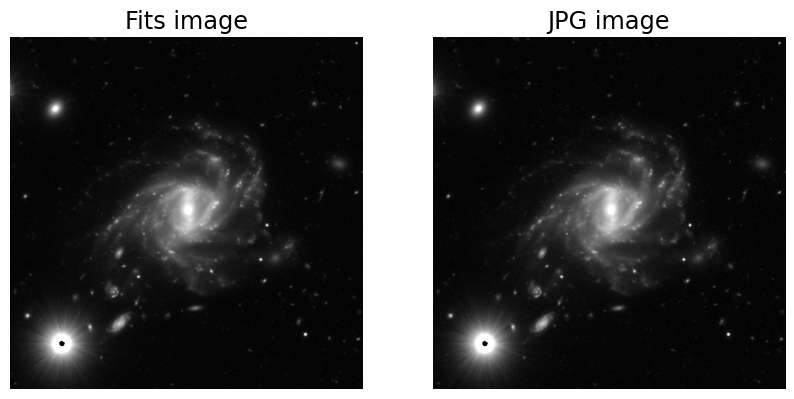

In [22]:
# getting saved FITS image
hdul = fits.open(output_folder + 'convert_cutout.fits')
image_data_fits = hdul[0].data

# getting saved jpg image
image_data_jpg = np.array(Image.open(output_folder + 'convert_cutout.jpg'))

# plotting side-by-side
fig = plt.figure(figsize=(10, 7))
plt.subplot(1, 2, 1)
plt.imshow(image_data_fits, cmap='gray', origin='lower', norm=ImageNormalize(image_data_fits, interval=PercentileInterval(99.5), stretch=AsinhStretch()))  
plt.axis('off')
plt.title("Fits image") 

plt.subplot(1, 2, 2)
plt.imshow(image_data_jpg, cmap='gray')  
plt.axis('off')
plt.title("JPG image") 

plt.show()

**Downsizing the jpg if necessary**

As the next step we downsize the jpg to create a thumbnail that is half the width and height of the original. You can see the documentation for the thumbnail function here: https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.thumbnail

Old img size: (600, 600)
New img size: (300, 300)


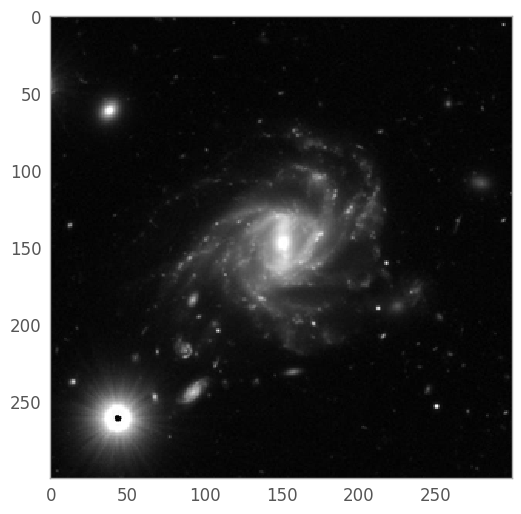

In [23]:
# downsizing the jpg
print("Old img size:", image_data_jpg.shape)
size_new = (image_data_jpg.shape[0]//2, image_data_jpg.shape[1]//2)
print("New img size:", size_new)
thumbnail = copy.deepcopy(Image.fromarray(image_data_jpg))
thumbnail.thumbnail(size_new, Image.Resampling.LANCZOS)
thumbnail.save(output_folder + "thumbnail.jpg")
plt.imshow(thumbnail, interpolation='nearest', cmap='gray')
plt.grid(False)
plt.show()

In [24]:
Euclid.logout()

INFO: Euclid TAP server logout OK [astroquery.esa.euclid.core]
INFO: Euclid data server logout OK [astroquery.esa.euclid.core]
INFO: Euclid cutout server logout OK [astroquery.esa.euclid.core]
INFO: Euclid sia server logout OK [astroquery.esa.euclid.core]


***

**Runnning the notebook outside of ESA Datalabs**

The current notebook was developed with the intent to use it inside ESA Datalabs, so all the filepaths point to the data volume mounted in ESA Datalabs. It is possible to modify the notebook to run outside of the platform if needed, but there are a few things to consider:

1. You need to install all the packages used in the notebook yourself
2. When trying to access any of the data, the products first need to be downloaded using Astroquery (due to the files being large this might take some time which is why using ESA Datalabs is advised)

You can download the product by using the Astroquery get_product method as shown below. You can find more information about using the function in the [Astroquery examples notebook](Astroquery.ipynb). After downloading the image you can run the rest of the notebook by substituting the Datalabs file path set in the beginning of the notebook with the one you set on you local machine.

`example_filename = 'EUC_MER_BGSUB-MOSAIC-VIS_TILE102158889-F95D3B_20241025T024806.508980Z_00.00.fits'`
`Euclid.get_product(file_name=example_filename, output_file=output_folder + 'local_file_name.fits')`